# K-Means Clustering

**Unsupervised learning:** Find groups in data without using labels.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.datasets import make_blobs, make_moons, load_wine
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score

plt.rcParams['figure.figsize'] = (8, 4.5)

## 1. How K-Means Works

Choose **K** groups. Repeat: **assign points to the nearest center → update each center**. The black X marks show the centers.

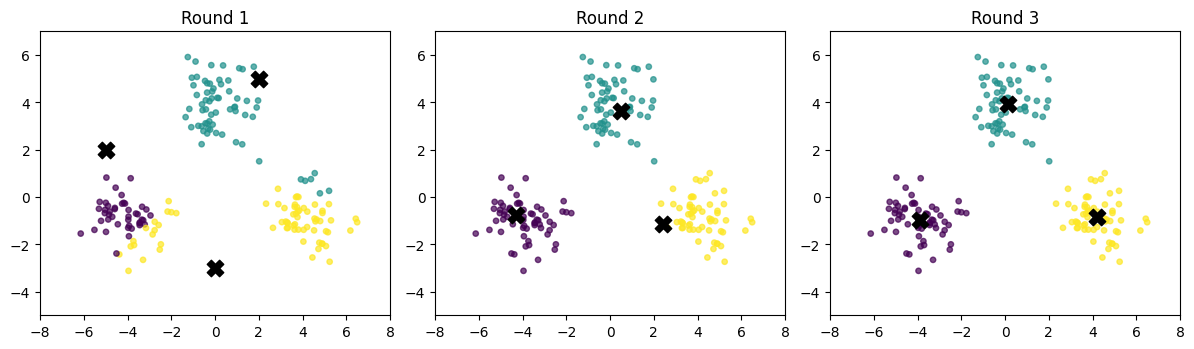

In [2]:
X, _ = make_blobs(n_samples=180, centers=[[-4, -1], [0, 4], [4, -1]],
                  cluster_std=0.9, random_state=4)

# Show a few rounds of "assign points, then update centers".
centers = np.array([[-5.0, 2.0], [2.0, 5.0], [0.0, -3.0]])
fig, axes = plt.subplots(1, 3, figsize=(12, 3.6))

for round_num, ax in enumerate(axes, start=1):
    distance = ((X[:, None, :] - centers[None, :, :]) ** 2).sum(axis=2)
    group = distance.argmin(axis=1)  # assign points to nearest center
    ax.scatter(X[:, 0], X[:, 1], c=group, cmap='viridis', s=15, alpha=0.7)
    ax.scatter(centers[:, 0], centers[:, 1], c='black', marker='X', s=140)
    ax.set_title(f'Round {round_num}')
    ax.set_xlim(-8, 8)
    ax.set_ylim(-5, 7)
    # Update centers to the mean of the points in each group.
    centers = np.array([X[group == k].mean(axis=0) for k in range(3)])

plt.tight_layout()
plt.show()

## 2. K-Means with scikit-learn

`n_clusters=3` sets **K = 3**. `fit_predict()` returns a cluster label for every point.

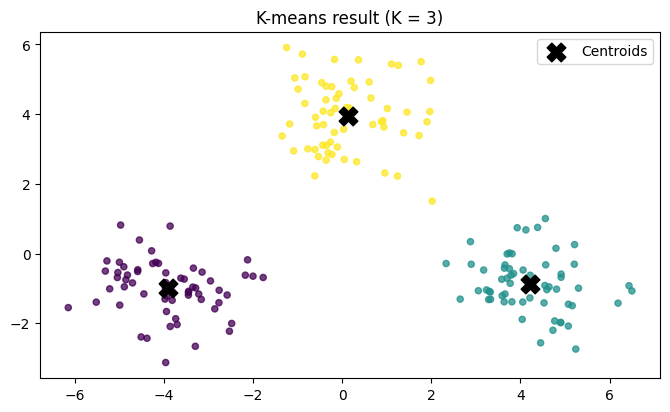

In [ ]:
model = KMeans(n_clusters=3, random_state=42)#, n_init=10)
labels = model.fit_predict(X)

plt.scatter(X[:, 0], X[:, 1], c=labels, cmap='viridis', s=20, alpha=0.75)
plt.scatter(model.cluster_centers_[:, 0], model.cluster_centers_[:, 1],
            c='black', marker='X', s=180, label='Centroids')
plt.title('K-means result (K = 3)')
plt.legend()
plt.show()

## 3. Wine Dataset

**178 wines, 13 features.** We scale the features first. PCA is only used for the 2D plots; true labels are shown only for comparison.

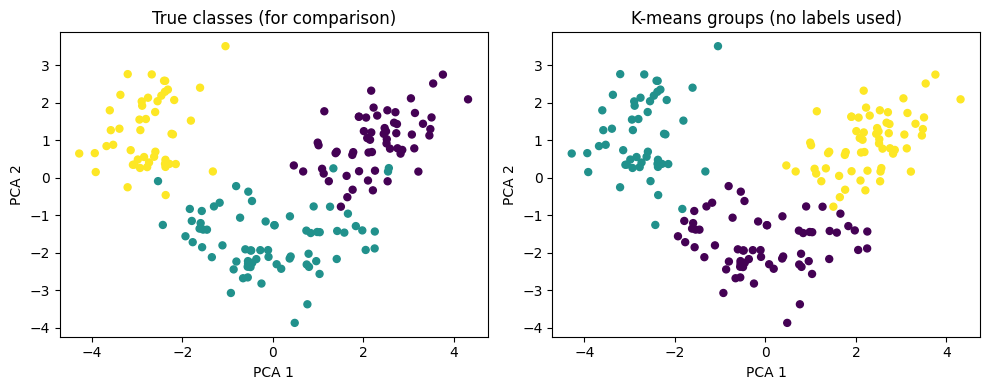

Data shape: (178, 13)
Reminder: cluster numbers do not need to match true class numbers.


In [4]:
wine = load_wine()
X_wine = StandardScaler().fit_transform(wine.data)
found = KMeans(n_clusters=3, random_state=42, n_init=10).fit_predict(X_wine)
X_picture = PCA(n_components=2).fit_transform(X_wine)

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].scatter(X_picture[:, 0], X_picture[:, 1], c=wine.target,
                cmap='viridis', s=25)
axes[0].set_title('True classes (for comparison)')
axes[1].scatter(X_picture[:, 0], X_picture[:, 1], c=found,
                cmap='viridis', s=25)
axes[1].set_title('K-means groups (no labels used)')
for ax in axes:
    ax.set_xlabel('PCA 1')
    ax.set_ylabel('PCA 2')
plt.tight_layout()
plt.show()

print('Data shape:', wine.data.shape)
print('Reminder: cluster numbers do not need to match true class numbers.')

## 4. Choosing K

**Silhouette score:** Higher scores usually mean clearer clusters. Try different values of K and compare their scores.

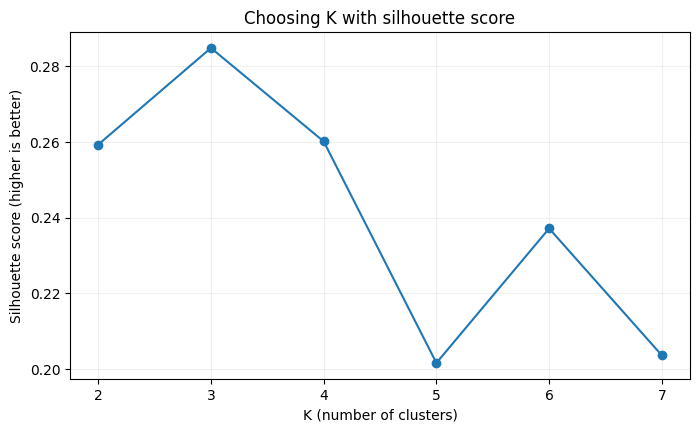

Best K among the values tested: 3


In [5]:
# Try several values of K and compare their silhouette scores.
ks = range(2, 8)
scores = []
for k in ks:
    km = KMeans(n_clusters=k, random_state=42, n_init=10).fit(X_wine)
    scores.append(silhouette_score(X_wine, km.labels_))

plt.plot(list(ks), scores, 'o-')
plt.title('Choosing K with silhouette score')
plt.xlabel('K (number of clusters)')
plt.ylabel('Silhouette score (higher is better)')
plt.xticks(list(ks))
plt.grid(alpha=0.2)
plt.show()

print('Best K among the values tested:', list(ks)[np.argmax(scores)])

## 5. Limitations

K-Means works best for roughly round, separated groups. It may not work well for curved shapes like these two moons.

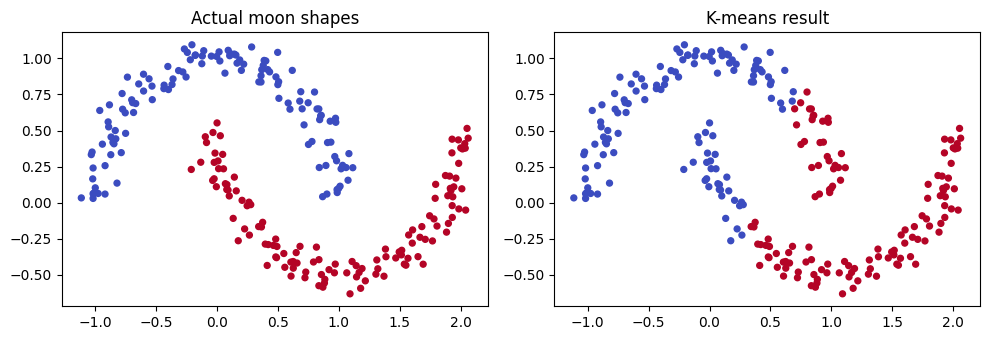

In [6]:
moons, true_groups = make_moons(n_samples=250, noise=0.07, random_state=42)
predicted_groups = KMeans(n_clusters=2, random_state=42, n_init=10).fit_predict(moons)

fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
axes[0].scatter(moons[:, 0], moons[:, 1], c=true_groups, cmap='coolwarm', s=18)
axes[0].set_title('Actual moon shapes')
axes[1].scatter(moons[:, 0], moons[:, 1], c=predicted_groups, cmap='coolwarm', s=18)
axes[1].set_title('K-means result')
plt.tight_layout()
plt.show()

**Takeaway:** K-Means groups data by distance, but the choice of K and the shape of the groups matter.